# **DATASET INFORMATION**


## 1. General Information
The dataset represents a log of bank transactions, capturing details about the transaction amounts, user demographics, device/location data, and account balances. 

* **Total Rows (Records):** 2,537
* **Total Columns (Features):** 16
* **Memory Usage:** ~317.2 KB

---

## 2. Data Dictionary & Structure
The dataset contains a mix of categorical (text) and numerical features. Below is the breakdown of the columns:

| Column Name | Data Type | Description / Observation |
| :--- | :--- | :--- |
| `TransactionID` | Object (Text) | Unique identifier for each transaction. |
| `AccountID` | Object (Text) | Unique identifier for the customer's bank account. |
| `TransactionAmount` | Float (Numeric) | The monetary value of the transaction. |
| `PreviousTransactionDate` | Object (Text) | Date and time of the user's last transaction before the current one. |
| `TransactionType` | Object (Text) | The type of transaction (e.g., *Debit*). |
| `Location` | Object (Text) | City or location where the transaction took place. |
| `DeviceID` | Object (Text) | Identifier for the device used to make the transaction. |
| `IP Address` | Object (Text) | The IP address associated with the transaction. |
| `MerchantID` | Object (Text) | Unique identifier for the merchant receiving the funds. |
| `Channel` | Object (Text) | The medium used for the transaction (e.g., *Branch*, *ATM*, *Online*). |
| `CustomerAge` | Float (Numeric) | The age of the account holder. |
| `CustomerOccupation` | Object (Text) | The profession or occupation status of the customer. |
| `TransactionDuration` | Float (Numeric) | The time taken to complete the transaction (likely in seconds). |
| `LoginAttempts` | Float (Numeric) | Number of login attempts made during the transaction session. |
| `AccountBalance` | Float (Numeric) | The balance of the account post-transaction or during the transaction. |
| `TransactionDate` | Object (Text) | The date and time when the current transaction occurred. |

---

## 3. Missing Values Analysis
There is a small amount of missing data across **every single column** in the dataset. Missing values represent roughly 0.7% to 1.1% of the data per column, which is quite low but requires handling (e.g., imputation or dropping) before machine learning modeling.

* **TransactionType, Location, DeviceID:** 30 missing values each.
* **TransactionID:** 29 missing values.
* **PreviousTransactionDate:** 28 missing values.
* **Channel, AccountBalance:** 27 missing values each.
* **TransactionAmount, TransactionDuration:** 26 missing values each.
* **TransactionDate:** 24 missing values.
* **MerchantID, CustomerOccupation:** 23 missing values each.
* **AccountID, LoginAttempts:** 21 missing values each.
* **IP Address:** 20 missing values.
* **CustomerAge:** 18 missing values.

---

## 4. Statistical Summary

### Numerical Features
| Feature | Mean (Average) | Min | 25% | Median (50%) | 75% | Max |
| :--- | :--- | :--- | :--- | :--- | :--- | :--- |
| **TransactionAmount** | 297.66 | 0.26 | 81.31 | 211.36 | 413.11 | 1,919.11 |
| **CustomerAge** | 44.68 | 18.0 | 27.0 | 45.0 | 59.0 | 80.0 |
| **TransactionDuration** | 119.42 | 10.0 | 63.0 | 112.0 | 161.0 | 300.0 |
| **LoginAttempts** | 1.12 | 1.0 | 1.0 | 1.0 | 1.0 | 5.0 |
| **AccountBalance** | 5,113.44 | 101.25 | 1,504.73 | 4,734.11 | 7,672.69| 14,977.99|

### Categorical Features
| Feature | Unique Categories | Most Frequent (Top) | Frequency of Top |
| :--- | :--- | :--- | :--- |
| **TransactionType** | 2 | Debit | 1,942 |
| **Channel** | 3 | Branch | 868 |
| **CustomerOccupation** | 4 | Student | 657 |
| **Location** | 43 | Fort Worth | 71 |
| **MerchantID** | 100 | M026 | 46 |
| **AccountID** | 495 | AC00363 | 12 |

---

## 5. Key Insights & Observations
1. **Transaction Patterns:** Most transactions in this dataset are **Debit** transactions. The primary channel used for transactions is a physical **Branch**, though there are 3 distinct channels available. 
2. **Demographics:** The customer base age spans evenly from young adults (18) to the elderly (80), with an average age of ~45. Interestingly, **Students** represent the most frequent occupation category within the dataset.
3. **Security/Fraud Indicators:** * The vast majority of sessions require only **1 login attempt**, but there is a maximum of **5 attempts**, which could be a useful feature for fraud detection or user friction analysis.
    * There are duplicate `TransactionID` values (2,484 unique IDs out of 2,508 non-null entries). This suggests either recurring transactions with the same base ID, an error in data logging, or a retry mechanism that logged the transaction twice.
4. **Data Formatting Needed:** Features like `PreviousTransactionDate` and `TransactionDate` are currently stored as "Object" (Text). For time-series analysis, they should be converted to standard `datetime` formats.

# **1. Environment Setup (Import Libraries)**
The first step is to load all the necessary Python libraries for data analysis, preprocessing, visualization, and Machine Learning modeling.


In [547]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from yellowbrick.cluster import KElbowVisualizer
try:
    import umap
    UMAP_AVAILABLE = True
except ImportError:
    UMAP_AVAILABLE = False
    print('umap-learn not installed. Run: pip install umap-learn')
import joblib

import os
os.makedirs('images', exist_ok=True)
os.makedirs('models', exist_ok=True)


# **2. Data Loading and Initial Inspection**
The dataset is loaded from an external source into a Pandas DataFrame. This step is crucial to ensure data integrity before further processing.


### 2.1 Load Data into DataFrame


In [548]:


url='https://docs.google.com/spreadsheets/d/e/2PACX-1vTbg5WVW6W3c8SPNUGc3A3AL-AG32TPEQGpdzARfNICMsLFI0LQj0jporhsLCeVhkN5AoRsTkn08AYl/pub?output=csv'
df = pd.read_csv(url)


### 2.2 Initial Data Inspection
Displaying the first few rows to understand the column structure and data values.


In [549]:
df.head(5)

,TransactionID,AccountID,TransactionAmount,PreviousTransactionDate,TransactionType,Location,DeviceID,IP Address,MerchantID,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance,TransactionDate
0,TX000001,AC00128,14.09,2023-04-11 16:29:14,Debit,San Diego,D000380,162.198.218.92,M015,ATM,70.0,Doctor,81.0,1.0,5112.21,2024-11-04 8:08:08
1,TX000002,AC00455,376.24,2023-06-27 16:44:19,Debit,Houston,D000051,13.149.61.4,M052,ATM,68.0,Doctor,141.0,1.0,13758.91,2024-11-04 8:09:35
2,TX000003,AC00019,126.29,2023-07-10 18:16:08,Debit,Mesa,D000235,215.97.143.157,M009,Online,19.0,Student,56.0,1.0,1122.35,2024-11-04 8:07:04
3,TX000004,AC00070,184.50,2023-05-05 16:32:11,Debit,Raleigh,D000187,200.13.225.150,M002,Online,26.0,Student,25.0,1.0,8569.06,2024-11-04 8:09:06
4,TX000005,AC00411,13.45,2023-10-16 17:51:24,Credit,Atlanta,D000308,65.164.3.100,M091,Online,NaN,Student,198.0,1.0,7429.40,2024-11-04 8:06:39


### 2.3 Data Structure Information
Checking the number of rows, columns, missing values, and data types (numeric or categorical).


In [550]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2537 entries, 0 to 2536
Data columns (total 16 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   TransactionID            2508 non-null   object 
 1   AccountID                2516 non-null   object 
 2   TransactionAmount        2511 non-null   float64
 3   PreviousTransactionDate  2509 non-null   object 
 4   TransactionType          2507 non-null   object 
 5   Location                 2507 non-null   object 
 6   DeviceID                 2507 non-null   object 
 7   IP Address               2517 non-null   object 
 8   MerchantID               2514 non-null   object 
 9   Channel                  2510 non-null   object 
 10  CustomerAge              2519 non-null   float64
 11  CustomerOccupation       2514 non-null   object 
 12  TransactionDuration      2511 non-null   float64
 13  LoginAttempts            2516 non-null   float64
 14  AccountBalance          

### 2.4 Basic Descriptive Statistics
Reviewing the mathematical summary (mean, min, max) of numerical features to understand the data distribution.


In [551]:
df.describe()

,TransactionAmount,CustomerAge,TransactionDuration,LoginAttempts,AccountBalance
count,2511.000000,2519.000000,2511.000000,2516.000000,2510.000000
mean,297.656468,44.678444,119.422939,1.121622,5113.438124
std,292.230367,17.837359,70.078513,0.594469,3897.975861
min,0.260000,18.000000,10.000000,1.000000,101.250000
25%,81.310000,27.000000,63.000000,1.000000,1504.727500
50%,211.360000,45.000000,112.000000,1.000000,4734.110000
75%,413.105000,59.000000,161.000000,1.000000,7672.687500
max,1919.110000,80.000000,300.000000,5.000000,14977.990000


### Correlation Heatmap
Visualize linear correlations between all numerical features to identify multicollinearity or strong associations before clustering.


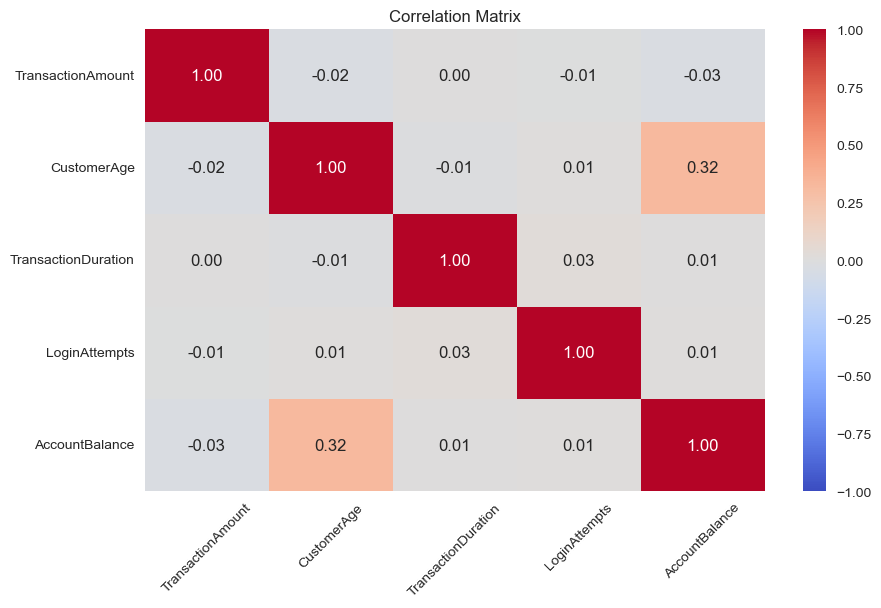

In [552]:

numerical_cols = df.select_dtypes(include=['number']).columns


correlation = df[numerical_cols].corr()

plt.figure(figsize=(10, 6))
sns.heatmap(correlation,
               annot=True,
               cmap='coolwarm',
               fmt=".2f",
               vmin=-1,
               vmax=1)
plt.xticks(rotation=45)
plt.title('Correlation Matrix')
plt.show()


### Distribution Histograms
Plot the distribution of all numerical columns to understand skewness and spread of the raw data.


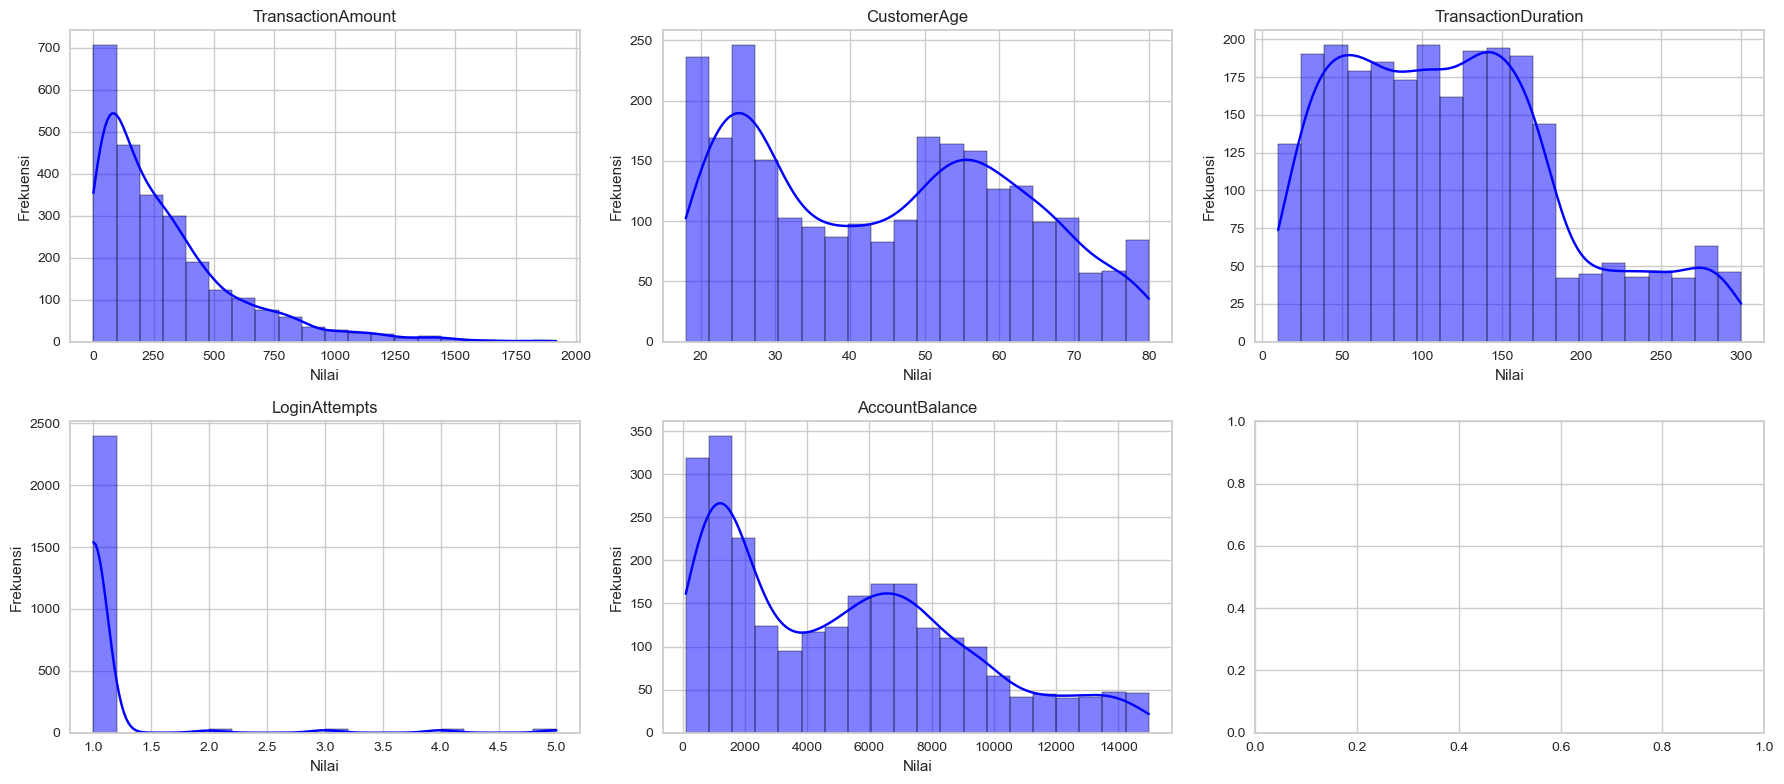

In [553]:

fig, axes = plt.subplots(2, 3, figsize=(18, 8))
axes = axes.flatten()

for i, column in enumerate(numerical_cols):
    sns.histplot(df[column], bins=20, kde=True, color='blue', ax=axes[i])
    axes[i].set_title(column)
    axes[i].set_xlabel("Nilai")
    axes[i].set_ylabel("Frekuensi")

\
plt.tight_layout()
plt.show()

### Advanced Visualization: Boxplot & Violinplot
Compare the distribution of transaction values across customer occupation groups to detect value differences between segments.


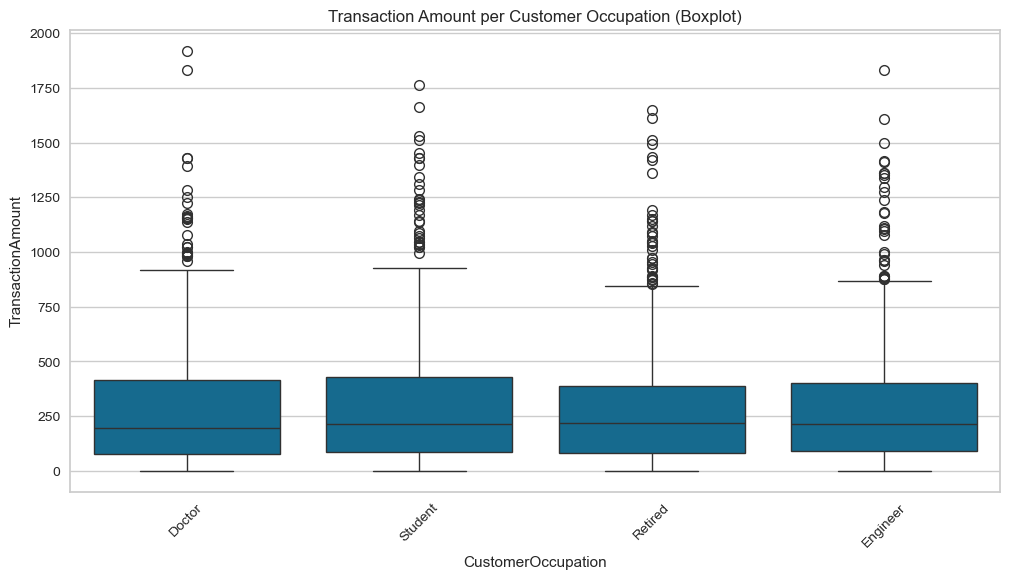

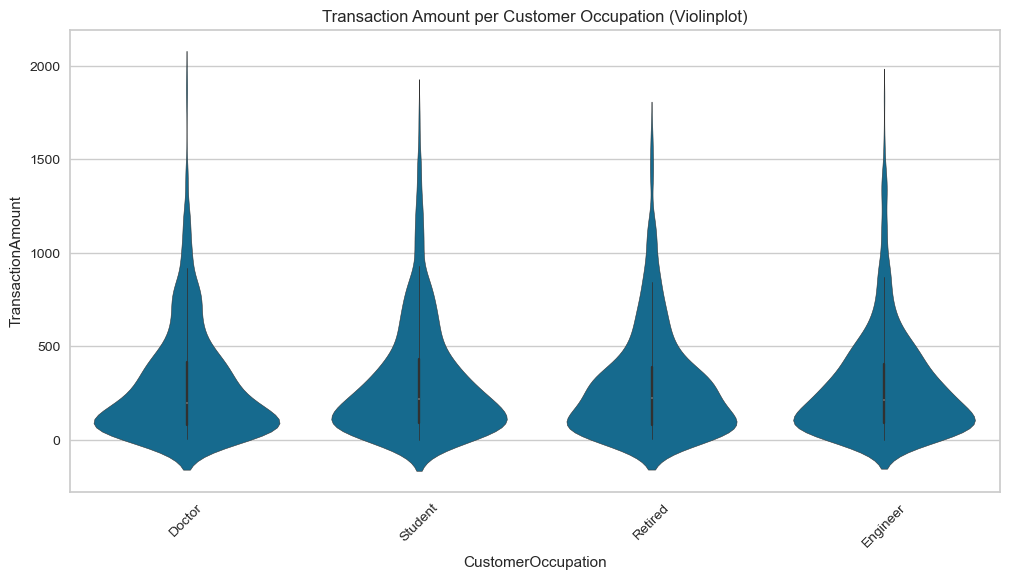

In [554]:
plt.figure(figsize=(12, 6))
sns.boxplot(x='CustomerOccupation', y='TransactionAmount', data=df)
plt.title("Transaction Amount per Customer Occupation (Boxplot)")
plt.xticks(rotation=45)
plt.show()



plt.figure(figsize=(12, 6))
sns.violinplot(x='CustomerOccupation', y='TransactionAmount', data=df)
plt.title("Transaction Amount per Customer Occupation (Violinplot)")
plt.xticks(rotation=45)
plt.show()

# **3. Data Preprocessing**
Raw data requires cleaning before it can be used to train a model. This stage covers:
1. Checking for missing (`null`) and duplicate records.
2. Dropping null/duplicate rows.
3. Dropping irrelevant columns (ID, address, date-related).
4. Encoding categorical features using `LabelEncoder()`.


### 3.1 Check for Missing Values
Identifying missing data cells, which can cause errors during mathematical modeling.


In [555]:
df.isnull().sum()

TransactionID              29
AccountID                  21
TransactionAmount          26
PreviousTransactionDate    28
TransactionType            30
Location                   30
DeviceID                   30
IP Address                 20
MerchantID                 23
Channel                    27
CustomerAge                18
CustomerOccupation         23
TransactionDuration        26
LoginAttempts              21
AccountBalance             27
TransactionDate            24
dtype: int64

### 3.2 Check for Duplicate Records


In [556]:
df.duplicated().sum()

np.int64(21)

### 3.3 Handle Missing Values
Drop all rows containing null or NaN values to prevent errors during model training.


In [557]:
df.dropna(inplace=True)
df.isnull().sum()

TransactionID              0
AccountID                  0
TransactionAmount          0
PreviousTransactionDate    0
TransactionType            0
Location                   0
DeviceID                   0
IP Address                 0
MerchantID                 0
Channel                    0
CustomerAge                0
CustomerOccupation         0
TransactionDuration        0
LoginAttempts              0
AccountBalance             0
TransactionDate            0
dtype: int64

### 3.4 Drop Duplicated Data


In [558]:
df.drop_duplicates(inplace=True)
df.duplicated().sum()

np.int64(0)

### 3.5 Drop Irrelevant Columns
Remove columns containing IDs, dates, and IP addresses. These are unique identifiers that add noise rather than meaningful patterns.


In [559]:
cols_to_drop = [col for col in df.columns if
                'id' in col.lower() or
                'ip' in col.lower() or
                'date' in col.lower()]

df = df.drop(columns=cols_to_drop)
df.head()

,TransactionAmount,TransactionType,Location,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance
0,14.09,Debit,San Diego,ATM,70.0,Doctor,81.0,1.0,5112.21
1,376.24,Debit,Houston,ATM,68.0,Doctor,141.0,1.0,13758.91
2,126.29,Debit,Mesa,Online,19.0,Student,56.0,1.0,1122.35
3,184.50,Debit,Raleigh,Online,26.0,Student,25.0,1.0,8569.06
5,92.15,Debit,Oklahoma City,ATM,18.0,Student,172.0,1.0,781.68


### 3.6 Label Encoding
Convert categorical text columns into numeric indices using `LabelEncoder()`. All encoders are stored in a dictionary for later inverse-transform.


In [560]:
categorical_cols = list(df.select_dtypes(include=['object']).columns)
encoders = {}

for column in categorical_cols:
    label_encoder = LabelEncoder()
    df[column] = label_encoder.fit_transform(df[column])
    encoders[column] = label_encoder

df.head()


,TransactionAmount,TransactionType,Location,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance
0,14.09,1,36,0,70.0,0,81.0,1.0,5112.21
1,376.24,1,15,0,68.0,0,141.0,1.0,13758.91
2,126.29,1,23,2,19.0,3,56.0,1.0,1122.35
3,184.50,1,33,2,26.0,3,25.0,1.0,8569.06
5,92.15,1,28,0,18.0,3,172.0,1.0,781.68


### 3.7 Final Feature List Check
Verify all remaining features are correctly included and data types are aligned.


In [561]:
df.columns.tolist()


['TransactionAmount',
 'TransactionType',
 'Location',
 'Channel',
 'CustomerAge',
 'CustomerOccupation',
 'TransactionDuration',
 'LoginAttempts',
 'AccountBalance']

# **4. Outlier Handling**
Outliers are extreme values that differ significantly from the majority of the data. The K-Means algorithm is highly sensitive to outliers as it relies on distance calculations. We will use the **Interquartile Range (IQR)** method to filter them out.
### 4.1 Data Visualization Before Handling Outliers

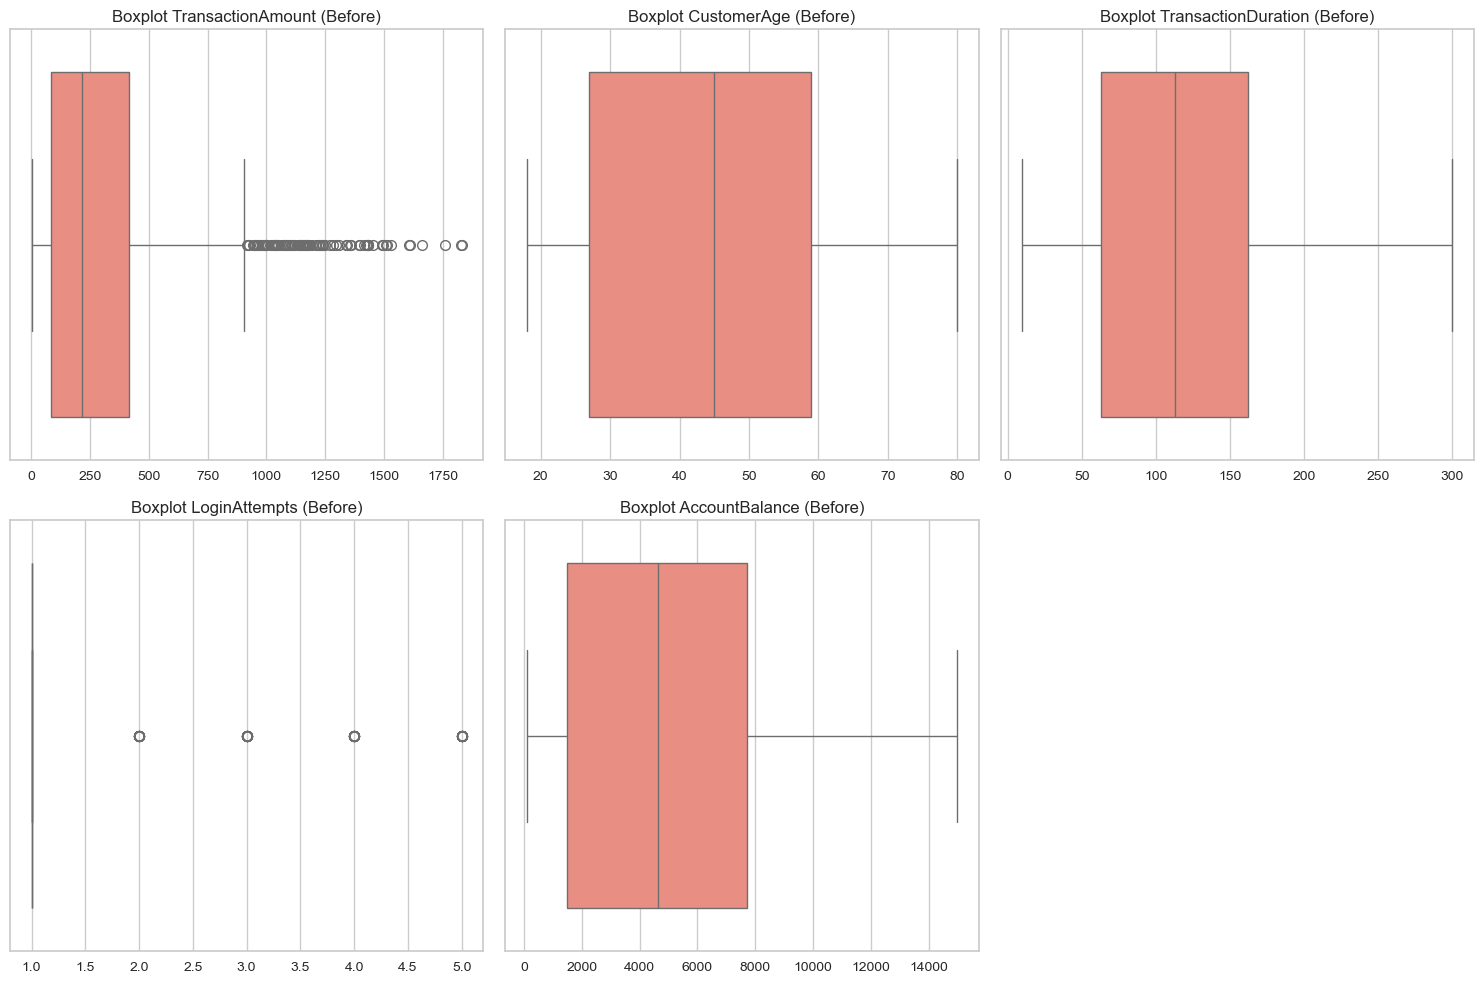

In [562]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(15, 10))
for i, col in enumerate(numerical_cols, 1):
    plt.subplot(2, 3, i)
    sns.boxplot(x=df[col], color='salmon')
    plt.title(f'Boxplot {col} (Before)')
    plt.xlabel('')
plt.tight_layout()
plt.show()

### 4.2 Filter Outliers using IQR


In [563]:
for col in numerical_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    df = df[(df[col] >= lower_bound) & (df[col] <= upper_bound)]
    
df.describe()

,TransactionAmount,TransactionType,Location,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance
count,1945.000000,1945.000000,1945.000000,1945.000000,1945.000000,1945.000000,1945.000000,1945.0,1945.000000
mean,256.838278,0.771722,21.299743,0.977378,44.693059,1.503342,119.225193,1.0,5100.811913
std,218.370197,0.419830,12.329250,0.804119,17.743453,1.135888,70.600647,0.0,3907.153333
min,0.260000,0.000000,0.000000,0.000000,18.000000,0.000000,10.000000,1.0,102.200000
25%,78.920000,1.000000,11.000000,0.000000,27.000000,0.000000,63.000000,1.0,1488.650000
50%,199.700000,1.000000,21.000000,1.000000,45.000000,1.000000,111.000000,1.0,4693.600000
75%,374.500000,1.000000,32.000000,2.000000,59.000000,3.000000,162.000000,1.0,7659.990000
max,903.190000,1.000000,42.000000,2.000000,80.000000,3.000000,300.000000,1.0,14977.990000


### 4.3 Data Visualization After Handling Outliers

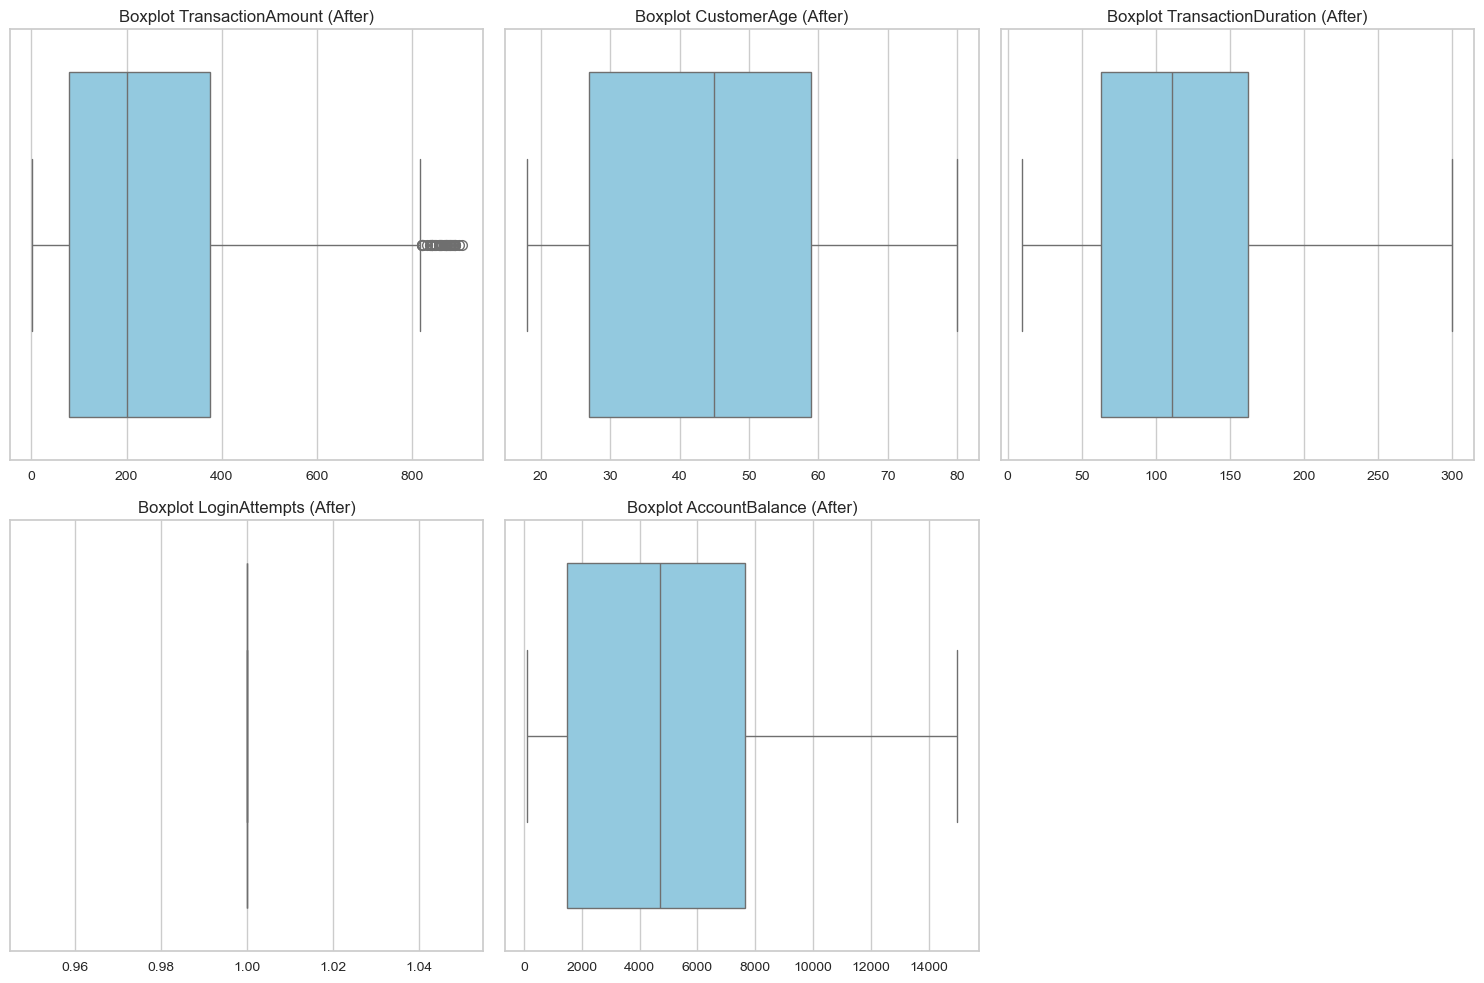

In [564]:
plt.figure(figsize=(15, 10))
for i, col in enumerate(numerical_cols, 1):
    plt.subplot(2, 3, i)
    sns.boxplot(x=df[col], color='skyblue')
    plt.title(f'Boxplot {col} (After)')
    plt.xlabel('')
plt.tight_layout()
plt.show()

# **5. Feature Engineering**
Enhance the dataset with new derived features and apply scaling to prepare it for clustering.


### 5.1 Feature Binning (Age Grouping)
Bin the continuous `CustomerAge` column into three categorical groups: Low, Medium, High. This helps the model capture generational behavioral patterns.


In [565]:
col_to_bin = 'CustomerAge'
new_col_name = 'Age_Group'
bin_labels = ['Low', 'Medium', 'High']
df[new_col_name] = pd.qcut(df[col_to_bin], q=3, labels=bin_labels, duplicates='drop')

label_encoder = LabelEncoder()
df[new_col_name] = label_encoder.fit_transform(df[new_col_name])

encoders[new_col_name] = label_encoder
if new_col_name not in categorical_cols:
    categorical_cols.append(new_col_name)

df.head(10)


,TransactionAmount,TransactionType,Location,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance,Age_Group
0,14.09,1,36,0,70.0,0,81.0,1.0,5112.21,0
1,376.24,1,15,0,68.0,0,141.0,1.0,13758.91,0
2,126.29,1,23,2,19.0,3,56.0,1.0,1122.35,1
3,184.50,1,33,2,26.0,3,25.0,1.0,8569.06,1
5,92.15,1,28,0,18.0,3,172.0,1.0,781.68,1
6,7.08,0,39,0,37.0,0,139.0,1.0,13316.71,2
7,171.42,0,16,1,67.0,2,291.0,1.0,2796.24,0
8,106.23,0,11,1,51.0,1,86.0,1.0,9095.14,2
9,815.96,1,26,0,55.0,0,120.0,1.0,1021.88,2
10,17.78,0,0,2,52.0,1,59.0,1.0,7599.52,2


### 5.2 Numerical Feature Standardization (StandardScaler)
Scale all numerical features to zero mean and unit variance. This prevents features with large value ranges from dominating the K-Means distance calculation.


In [566]:
scaler = StandardScaler()
df[numerical_cols] = scaler.fit_transform(df[numerical_cols])

df.head()


,TransactionAmount,TransactionType,Location,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance,Age_Group
0,-1.111922,1,36,0,1.426636,0,-0.541568,0.0,0.002918,0
1,0.546926,1,15,0,1.313889,0,0.308502,0.0,2.216531,0
2,-0.597984,1,23,2,-1.448403,3,-0.895763,0.0,-1.018513,1
3,-0.331350,1,33,2,-1.053790,3,-1.334965,0.0,0.887895,1
5,-0.754364,1,28,0,-1.504776,3,0.747704,0.0,-1.105726,1


# **6. Clustering Modeling (K-Means)**
Build the clustering model using the preprocessed dataset. Steps:
1. Use the fully preprocessed DataFrame as input.
2. Apply the Elbow Method to determine the optimal number of clusters `k`.
3. Train the final K-Means model using `sklearn.cluster.KMeans()`.
4. Save the trained model using `joblib.dump()`.

### 6.0 Verify Preprocessed Dataset
Run `describe()` to confirm that all features are properly scaled and ready for clustering.

In [567]:
df.describe()

,TransactionAmount,TransactionType,Location,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance,Age_Group
count,1.945000e+03,1945.000000,1945.000000,1945.000000,1.945000e+03,1945.000000,1.945000e+03,1945.0,1.945000e+03,1945.000000
mean,-8.402305e-17,0.771722,21.299743,0.977378,-1.269479e-16,1.503342,2.557223e-17,0.0,-6.027740e-17,1.001028
std,1.000257e+00,0.419830,12.329250,0.804119,1.000257e+00,1.135888,1.000257e+00,0.0,1.000257e+00,0.810171
min,-1.175271e+00,0.000000,0.000000,0.000000,-1.504776e+00,0.000000,-1.547483e+00,0.0,-1.279678e+00,0.000000
25%,-8.149648e-01,1.000000,11.000000,0.000000,-9.974163e-01,0.000000,-7.965883e-01,0.0,-9.247374e-01,0.000000
50%,-2.617251e-01,1.000000,21.000000,1.000000,1.730327e-02,1.000000,-1.165330e-01,0.0,-1.042490e-01,1.000000
75%,5.389562e-01,1.000000,32.000000,2.000000,8.065296e-01,3.000000,6.060257e-01,0.0,6.551666e-01,2.000000
max,2.960651e+00,1.000000,42.000000,2.000000,1.990369e+00,3.000000,2.561185e+00,0.0,2.528623e+00,2.000000


In [568]:
df_used = df.copy()
df_used.describe()


,TransactionAmount,TransactionType,Location,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance,Age_Group
count,1.945000e+03,1945.000000,1945.000000,1945.000000,1.945000e+03,1945.000000,1.945000e+03,1945.0,1.945000e+03,1945.000000
mean,-8.402305e-17,0.771722,21.299743,0.977378,-1.269479e-16,1.503342,2.557223e-17,0.0,-6.027740e-17,1.001028
std,1.000257e+00,0.419830,12.329250,0.804119,1.000257e+00,1.135888,1.000257e+00,0.0,1.000257e+00,0.810171
min,-1.175271e+00,0.000000,0.000000,0.000000,-1.504776e+00,0.000000,-1.547483e+00,0.0,-1.279678e+00,0.000000
25%,-8.149648e-01,1.000000,11.000000,0.000000,-9.974163e-01,0.000000,-7.965883e-01,0.0,-9.247374e-01,0.000000
50%,-2.617251e-01,1.000000,21.000000,1.000000,1.730327e-02,1.000000,-1.165330e-01,0.0,-1.042490e-01,1.000000
75%,5.389562e-01,1.000000,32.000000,2.000000,8.065296e-01,3.000000,6.060257e-01,0.0,6.551666e-01,2.000000
max,2.960651e+00,1.000000,42.000000,2.000000,1.990369e+00,3.000000,2.561185e+00,0.0,2.528623e+00,2.000000


### 6.1 Determine Optimal Clusters (Elbow Method)
Use `KElbowVisualizer` with the Silhouette metric to find the optimal number of clusters `k`.

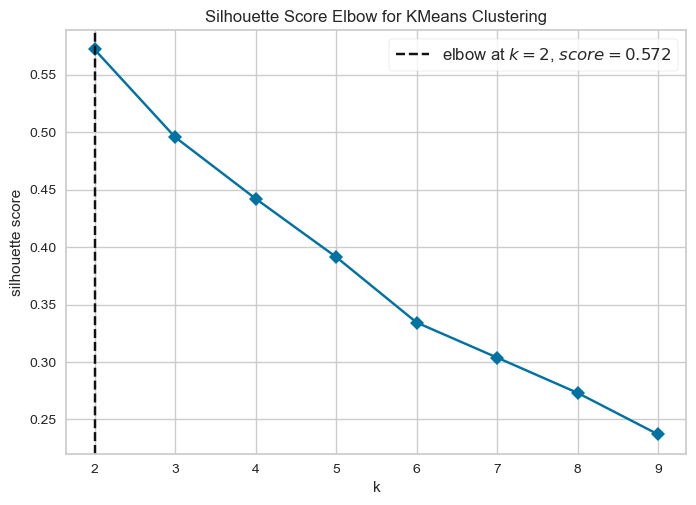

<Axes: title={'center': 'Silhouette Score Elbow for KMeans Clustering'}, xlabel='k', ylabel='silhouette score'>

In [569]:
model = KMeans()
visualizer = KElbowVisualizer(model,
                       k=(2,10),
                       metric='silhouette',
                       timings=False)

visualizer.fit(df)
visualizer.show()

### 6.2 Train K-Means Model
Fit the K-Means model using the optimal number of clusters determined by the Elbow Method.

In [570]:
model = KMeans(n_clusters=2, random_state=42)
model.fit(df)

,n_clusters,2
,init,'k-means++'
,n_init,'auto'
,max_iter,300
,tol,0.0001
,verbose,0
,random_state,42
,copy_x,True
,algorithm,'lloyd'


### 6.3 Save Trained Model
Persist the trained K-Means model to a `.h5` file using `joblib` for future inference without retraining.

In [571]:
joblib.dump(model, "models/model_clustering.h5")

['models/model_clustering.h5']

### 6.4 Evaluate Cluster Quality (Silhouette Score)
This score measures how dense a cluster is and how well it is separated from other clusters. A score close to 1 indicates excellent separation.

In [572]:
labels = model.labels_
score = silhouette_score(df, labels)
print("K-Means Silhouette Score:", score)

K-Means Silhouette Score: 0.5719840690144938


### 6.5 Algorithm Comparison
To validate our approach, we compare K-Means performance with DBSCAN, Hierarchical Clustering, and GMM to ensure it is the best choice for this dataset.

In [573]:
# Initialize list to store results
clustering_results = []

# 1. K-Means (Already trained)
clustering_results.append({"Model": "K-Means", "Silhouette Score": score})

# 2. DBSCAN (Density-Based Spatial Clustering)
dbscan = DBSCAN(eps=0.5, min_samples=5)
db_labels = dbscan.fit_predict(df)
if len(set(db_labels)) > 1:
    db_score = silhouette_score(df, db_labels)
    clustering_results.append({"Model": "DBSCAN", "Silhouette Score": db_score})
else:
    clustering_results.append({"Model": "DBSCAN", "Silhouette Score": "N/A (Only 1 Cluster)"})

# 3. Hierarchical Clustering (Agglomerative)
hc = AgglomerativeClustering(n_clusters=2)
hc_labels = hc.fit_predict(df)
hc_score = silhouette_score(df, hc_labels)
clustering_results.append({"Model": "Hierarchical", "Silhouette Score": hc_score})

# 4. GMM (Gaussian Mixture Model)
gmm = GaussianMixture(n_components=2, random_state=42)
gmm_labels = gmm.fit_predict(df)
gmm_score = silhouette_score(df, gmm_labels)
clustering_results.append({"Model": "GMM", "Silhouette Score": gmm_score})

# Display Comparison Table
df_comparison = pd.DataFrame(clustering_results)
print("\nModel Performance Comparison:")
print(df_comparison)


Model Performance Comparison:
          Model      Silhouette Score
0       K-Means              0.571984
1        DBSCAN  N/A (Only 1 Cluster)
2  Hierarchical               0.54778
3           GMM              0.558882


### 6.6 2D Cluster Visualization (using PCA)
Since customer data has many dimensions (columns), we use Principal Component Analysis (PCA) to reduce it to 2 main axes (X and Y) for Scatter Plot visualization.

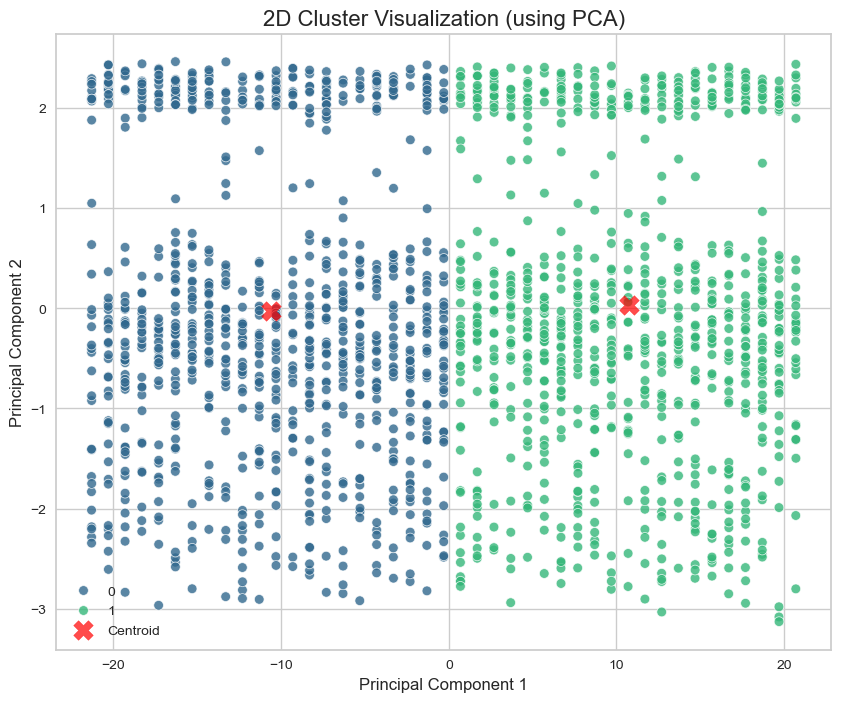

In [574]:
pca = PCA(n_components=2)
df_pca = pca.fit_transform(df)
df_pca = pd.DataFrame(data=df_pca, columns=['Principal Component 1', 'Principal Component 2'])
df_pca['Cluster'] = model.labels_

plt.figure(figsize=(10, 8))
sns.scatterplot(
    x='Principal Component 1',
    y='Principal Component 2',
    hue='Cluster',  
    palette=sns.color_palette("viridis", n_colors=2), 
    data=df_pca,
    legend="full",
    alpha=0.8
)


plt.title('2D Cluster Visualization (using PCA)', fontsize=16)
plt.xlabel('Principal Component 1', fontsize=12)
plt.ylabel('Principal Component 2', fontsize=12)
centers = pca.transform(model.cluster_centers_)
plt.scatter(centers[:, 0], centers[:, 1], c='red', s=200, alpha=0.7, marker='X', label='Centroid')
plt.legend()
plt.show()

# **7. Alternative: PCA-Based Clustering**
Testing an alternative approach where the K-Means algorithm is trained directly on the data simplified by PCA (only 2 core components), rather than the original dataset.

In [575]:
pca = PCA(n_components=2)
df_pca_array = pca.fit_transform(df_used)
data_final = pd.DataFrame(data=df_pca_array, columns=['PCA1', 'PCA2'])
kmeans_pca = KMeans(n_clusters=3, random_state=42)
kmeans_pca.fit(data_final)

,n_clusters,3
,init,'k-means++'
,n_init,'auto'
,max_iter,300
,tol,0.0001
,verbose,0
,random_state,42
,copy_x,True
,algorithm,'lloyd'


### 7.1 Save PCA-Based K-Means Model

In [576]:
joblib.dump(kmeans_pca, "models/PCA_model_clustering.h5")


['models/PCA_model_clustering.h5']

### 7.2 Evaluate PCA Model

In [577]:
# Calculate Silhouette Score for the PCA-based K-Means model
labels_pca = kmeans_pca.labels_
score_pca = silhouette_score(data_final, labels_pca)

print(f"Silhouette Score (after PCA): {score_pca}")

Silhouette Score (after PCA): 0.5509022714771943


# **8. Business Interpretation & Classification Prep**
The most critical stage for business needs: translating the numbers back into human language to understand the true profile of each customer group.

### 8.1 Assign Cluster Labels
Attach the cluster labels from the trained K-Means model to the original dataset for further analysis.

In [578]:
df_used['Cluster'] = model.labels_
df_used.head()

,TransactionAmount,TransactionType,Location,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance,Age_Group,Cluster
0,-1.111922,1,36,0,1.426636,0,-0.541568,0.0,0.002918,0,1
1,0.546926,1,15,0,1.313889,0,0.308502,0.0,2.216531,0,0
2,-0.597984,1,23,2,-1.448403,3,-0.895763,0.0,-1.018513,1,1
3,-0.331350,1,33,2,-1.053790,3,-1.334965,0.0,0.887895,1,1
5,-0.754364,1,28,0,-1.504776,3,0.747704,0.0,-1.105726,1,1


### 8.2 Cluster Profile (Scaled Data Version)
Reviewing the average characteristics of the groups while the data is still in its transformed, scaled state.

In [579]:
agg_summary = df_used.groupby('Cluster')[numerical_cols].agg(['mean', 'min', 'max']).round(2).T
display(agg_summary)

Cluster                      0     1
TransactionAmount   mean -0.01  0.01
                    min  -1.17 -1.18
                    max   2.96  2.90
CustomerAge         mean  0.02 -0.02
                    min  -1.50 -1.50
                    max   1.99  1.99
TransactionDuration mean  0.03 -0.03
                    min  -1.55 -1.55
                    max   2.56  2.55
LoginAttempts       mean  0.00  0.00
                    min   0.00  0.00
                    max   0.00  0.00
AccountBalance      mean  0.01 -0.01
                    min  -1.28 -1.28
                    max   2.52  2.53

### 8.3 Prepare Target Variable for Classification
Renaming the 'Cluster' column to 'Target'. This is an absolute prerequisite if this dataset will be used to train a Predictive Classification model (Supervised Learning) in the future.

In [580]:
df_used.rename(columns={"Cluster": "Target"}, inplace=True)
df_used.head()


,TransactionAmount,TransactionType,Location,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance,Age_Group,Target
0,-1.111922,1,36,0,1.426636,0,-0.541568,0.0,0.002918,0,1
1,0.546926,1,15,0,1.313889,0,0.308502,0.0,2.216531,0,0
2,-0.597984,1,23,2,-1.448403,3,-0.895763,0.0,-1.018513,1,1
3,-0.331350,1,33,2,-1.053790,3,-1.334965,0.0,0.887895,1,1
5,-0.754364,1,28,0,-1.504776,3,0.747704,0.0,-1.105726,1,1


### 8.4 Export Preprocessed Data

In [581]:
df_used.to_csv('data_clustering.csv', index=False)

### 8.5 Inverse Transform (Numerical)
Reverting the normalized numerical values (from StandardScaler) back to their original nominal values (e.g., actual Balance in Dollars).

In [582]:
df_inverse = df_used.copy()
df_inverse[numerical_cols] = scaler.inverse_transform(df_inverse[numerical_cols])

df_inverse.head()


,TransactionAmount,TransactionType,Location,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance,Age_Group,Target
0,14.09,1,36,0,70.0,0,81.0,1.0,5112.21,0,1
1,376.24,1,15,0,68.0,0,141.0,1.0,13758.91,0,0
2,126.29,1,23,2,19.0,3,56.0,1.0,1122.35,1,1
3,184.50,1,33,2,26.0,3,25.0,1.0,8569.06,1,1
5,92.15,1,28,0,18.0,3,172.0,1.0,781.68,1,1


### 8.6 Inverse Transform (Categorical)
Reverting the index values (0, 1) back to their original text labels (e.g., 'Debit', 'Doctor') for human readability.

In [583]:
for column in categorical_cols:
    encoder = encoders[column]
    df_inverse[column] = encoder.inverse_transform(df_inverse[column].astype(int))

df_inverse.head()


,TransactionAmount,TransactionType,Location,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance,Age_Group,Target
0,14.09,Debit,San Diego,ATM,70.0,Doctor,81.0,1.0,5112.21,High,1
1,376.24,Debit,Houston,ATM,68.0,Doctor,141.0,1.0,13758.91,High,0
2,126.29,Debit,Mesa,Online,19.0,Student,56.0,1.0,1122.35,Low,1
3,184.50,Debit,Raleigh,Online,26.0,Student,25.0,1.0,8569.06,Low,1
5,92.15,Debit,Oklahoma City,ATM,18.0,Student,172.0,1.0,781.68,Low,1


### 8.7 Final Customer Segment Profiles
This is the most crucial table for business analysts. It displays the average, minimum, and maximum values of each customer segment using **real-world values**, enabling the formulation of marketing strategies.

In [584]:
agg_summary_num = df_inverse.groupby('Target')[numerical_cols].agg(['mean', 'min', 'max']).round(2).T
agg_summary_cat = df_inverse.groupby('Target')[categorical_cols].agg(lambda x: x.mode()[0]).round(2).T

display(agg_summary_num)
display(agg_summary_cat)

Target                           0         1
TransactionAmount   mean    255.55    258.15
                    min       0.32      0.26
                    max     903.19    889.01
CustomerAge         mean     45.06     44.33
                    min      18.00     18.00
                    max      80.00     80.00
TransactionDuration mean    121.12    117.30
                    min      10.00     10.00
                    max     300.00    299.00
LoginAttempts       mean      1.00      1.00
                    min       1.00      1.00
                    max       1.00      1.00
AccountBalance      mean   5142.17   5058.81
                    min     117.98    102.20
                    max   14942.78  14977.99

Target,0,1
TransactionType,Debit,Debit
Location,Charlotte,Tucson
Channel,Branch,Branch
CustomerOccupation,Doctor,Student
Age_Group,Medium,Low


In [585]:
df_inverse.head(10)

,TransactionAmount,TransactionType,Location,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance,Age_Group,Target
0,14.09,Debit,San Diego,ATM,70.0,Doctor,81.0,1.0,5112.21,High,1
1,376.24,Debit,Houston,ATM,68.0,Doctor,141.0,1.0,13758.91,High,0
2,126.29,Debit,Mesa,Online,19.0,Student,56.0,1.0,1122.35,Low,1
3,184.50,Debit,Raleigh,Online,26.0,Student,25.0,1.0,8569.06,Low,1
5,92.15,Debit,Oklahoma City,ATM,18.0,Student,172.0,1.0,781.68,Low,1
6,7.08,Credit,Seattle,ATM,37.0,Doctor,139.0,1.0,13316.71,Medium,1
7,171.42,Credit,Indianapolis,Branch,67.0,Retired,291.0,1.0,2796.24,High,0
8,106.23,Credit,Detroit,Branch,51.0,Engineer,86.0,1.0,9095.14,Medium,0
9,815.96,Debit,Nashville,ATM,55.0,Doctor,120.0,1.0,1021.88,Medium,1
10,17.78,Credit,Albuquerque,Online,52.0,Engineer,59.0,1.0,7599.52,Medium,0


### 8.8 Identify Customers by Cluster
Here is how you technically extract and view the original customer data based on the cluster they belong to.

In [586]:
# Display the first 5 customers belonging to Cluster 0
cluster_0_customers = df_inverse[df_inverse['Target'] == 0]
print(f"Total Customers in Cluster 0: {len(cluster_0_customers)}")
display(cluster_0_customers.head())

# Display the first 5 customers belonging to Cluster 1
cluster_1_customers = df_inverse[df_inverse['Target'] == 1]
print(f"\nTotal Customers in Cluster 1: {len(cluster_1_customers)}")
display(cluster_1_customers.head())

Total Customers in Cluster 0: 980


,TransactionAmount,TransactionType,Location,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance,Age_Group,Target
1,376.24,Debit,Houston,ATM,68.0,Doctor,141.0,1.0,13758.91,High,0
7,171.42,Credit,Indianapolis,Branch,67.0,Retired,291.0,1.0,2796.24,High,0
8,106.23,Credit,Detroit,Branch,51.0,Engineer,86.0,1.0,9095.14,Medium,0
10,17.78,Credit,Albuquerque,Online,52.0,Engineer,59.0,1.0,7599.52,Medium,0
14,166.99,Debit,Louisville,Online,18.0,Student,134.0,1.0,299.93,Low,0



Total Customers in Cluster 1: 965


,TransactionAmount,TransactionType,Location,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance,Age_Group,Target
0,14.09,Debit,San Diego,ATM,70.0,Doctor,81.0,1.0,5112.21,High,1
2,126.29,Debit,Mesa,Online,19.0,Student,56.0,1.0,1122.35,Low,1
3,184.50,Debit,Raleigh,Online,26.0,Student,25.0,1.0,8569.06,Low,1
5,92.15,Debit,Oklahoma City,ATM,18.0,Student,172.0,1.0,781.68,Low,1
6,7.08,Credit,Seattle,ATM,37.0,Doctor,139.0,1.0,13316.71,Medium,1


# **9. Extended Cluster Evaluation**
Evaluate the best clustering model using three complementary metrics:
- **Silhouette Score** — intra-cluster cohesion vs inter-cluster separation (higher is better)
- **Davies-Bouldin Index** — average similarity to the most similar cluster (lower is better)
- **Calinski-Harabasz Index** — ratio of between- to within-cluster variance (higher is better)

In [587]:
# Retrieve the scaled feature matrix used for clustering
X_eval = df.values  # already scaled at this point
best_labels = model.labels_

sil = silhouette_score(X_eval, best_labels)
dbi = davies_bouldin_score(X_eval, best_labels)
chi = calinski_harabasz_score(X_eval, best_labels)

print('Extended Cluster Evaluation (Best Model: K-Means)')
print(f'  Silhouette Score      : {sil:.4f}  (higher is better)')
print(f'  Davies-Bouldin Index  : {dbi:.4f}  (lower is better)')
print(f'  Calinski-Harabasz     : {chi:.2f}  (higher is better)')

Extended Cluster Evaluation (Best Model: K-Means)
  Silhouette Score      : 0.5720  (higher is better)
  Davies-Bouldin Index  : 0.5818  (lower is better)
  Calinski-Harabasz     : 4880.81  (higher is better)


# **10. Anomaly Score - Distance to Nearest Centroid**
Compute the distance of each data point to its assigned cluster centroid to identify potential anomalies.

Anomaly Score Statistics:
count    1945.0000
mean        6.1996
std         2.5993
min         1.5864
25%         3.8851
50%         5.9938
75%         8.4070
max        11.3085
Name: anomaly_score, dtype: float64


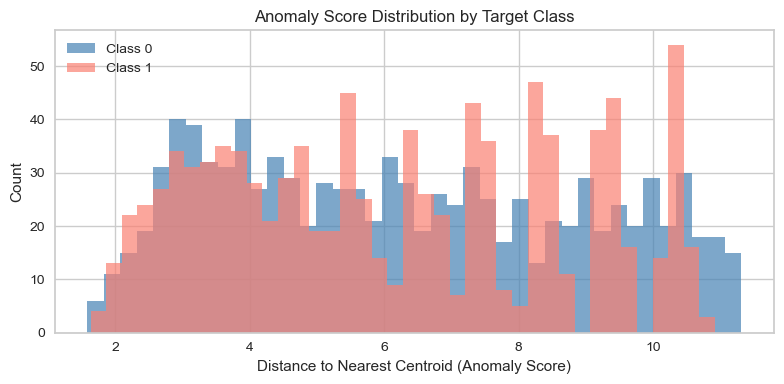

In [588]:
X_for_score = df.values  # scaled feature matrix

distances = model.transform(X_for_score)
df_inverse['anomaly_score'] = distances.min(axis=1)

print('Anomaly Score Statistics:')
print(df_inverse['anomaly_score'].describe().round(4))

fig, ax = plt.subplots(figsize=(8, 4))
for target_val, color in [(0, 'steelblue'), (1, 'salmon')]:
    subset = df_inverse[df_inverse['Target'] == target_val]['anomaly_score']
    ax.hist(subset, bins=40, alpha=0.7, color=color, label=f'Class {target_val}')
ax.set_title('Anomaly Score Distribution by Target Class')
ax.set_xlabel('Distance to Nearest Centroid (Anomaly Score)')
ax.set_ylabel('Count')
ax.legend()
plt.tight_layout()
plt.savefig('images/anomaly_score_dist.png', dpi=150)
plt.show()

# **11. UMAP Visualization**
**UMAP (Uniform Manifold Approximation and Projection)** is a non-linear dimensionality reduction technique
that preserves both local and global data structure better than PCA.
It produces clearer cluster separations in 2D, making it easier to visually validate cluster quality.
> Install with: `pip install umap-learn`

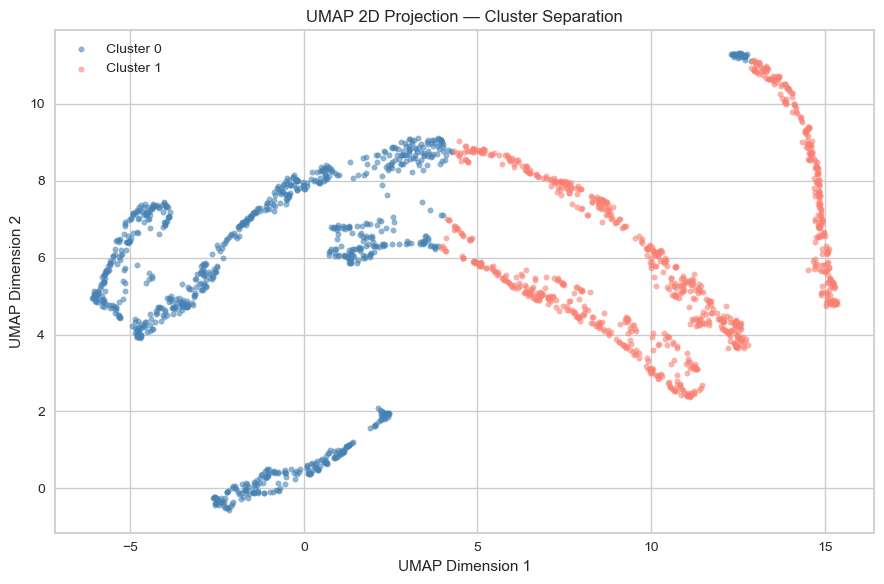

In [589]:
if UMAP_AVAILABLE:
    reducer = umap.UMAP(n_components=2, random_state=42, n_neighbors=15, min_dist=0.1)
    X_umap = reducer.fit_transform(X_for_score)

    palette = {0: 'steelblue', 1: 'salmon'}
    fig, ax = plt.subplots(figsize=(9, 6))
    for label, color in palette.items():
        mask = df_inverse['Target'] == label
        ax.scatter(
            X_umap[mask, 0], X_umap[mask, 1],
            c=color, label=f'Cluster {label}', alpha=0.6, s=15
        )
    ax.set_title('UMAP 2D Projection — Cluster Separation')
    ax.set_xlabel('UMAP Dimension 1')
    ax.set_ylabel('UMAP Dimension 2')
    ax.legend()
    plt.tight_layout()
    plt.savefig('images/umap_clusters.png', dpi=150)
    plt.show()
else:
    print('UMAP not available. Install with: pip install umap-learn')

# **12. Export Final Dataset**
Export the inverse-transformed data with `Target` labels and `anomaly_score` to CSV.
This file is the direct input for the Classification pipeline.

In [590]:
df_inverse.to_csv('data_clustering_inverse.csv', index=False)
print(f'Exported {len(df_inverse):,} rows with {df_inverse.shape[1]} columns.')
print('Columns:', df_inverse.columns.tolist())

Exported 1,945 rows with 12 columns.
Columns: ['TransactionAmount', 'TransactionType', 'Location', 'Channel', 'CustomerAge', 'CustomerOccupation', 'TransactionDuration', 'LoginAttempts', 'AccountBalance', 'Age_Group', 'Target', 'anomaly_score']
